In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 M

STEP 2. Parameterized Quantum Circuit
        ┌───────┐ ░ ┌─┐
     q: ┤ Ry(θ) ├─░─┤M├
        └───────┘ ░ └╥┘
meas: 1/═════════════╩═
                     0 


STEP 3. Aer Simulator
Backend : AerSimulator('aer_simulator')
Shots   : 2048


STEP 4. Prediction Function


STEP 5. Prediction Test
Theta : 0.000
Prediction : 1.0000
----------------------------------------
Theta : 1.571
Prediction : 0.0273
----------------------------------------
Theta : 3.142
Prediction : -1.0000
----------------------------------------


STEP 6. Target
Target : -0.8


STEP 7. Objective Function
Objective Function 생성 완료


STEP 8. Objective Function Test
Theta      : 0.100
Prediction : 0.9941
Loss       : 3.222446
--------------------------------------------------
Theta      : 1.000
Prediction : 0.5049
Loss       : 1.808815
--------------------------------------------------
Theta      : 2.500
Prediction : -0.7979
Loss       : 0.000905
--------------------------------------------------


STEP 9. Parameter Sweep

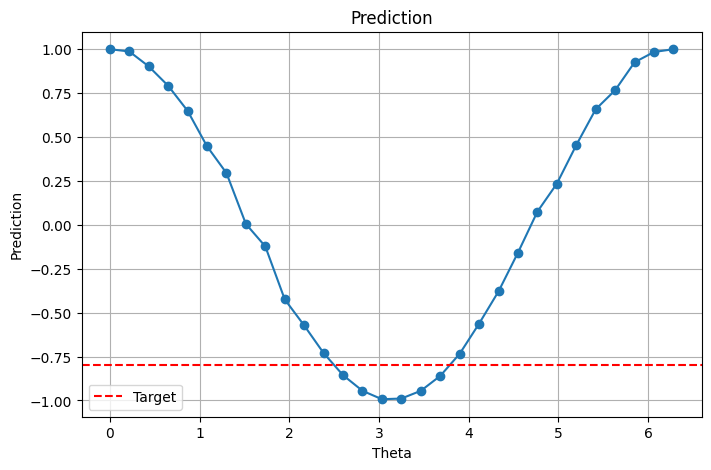

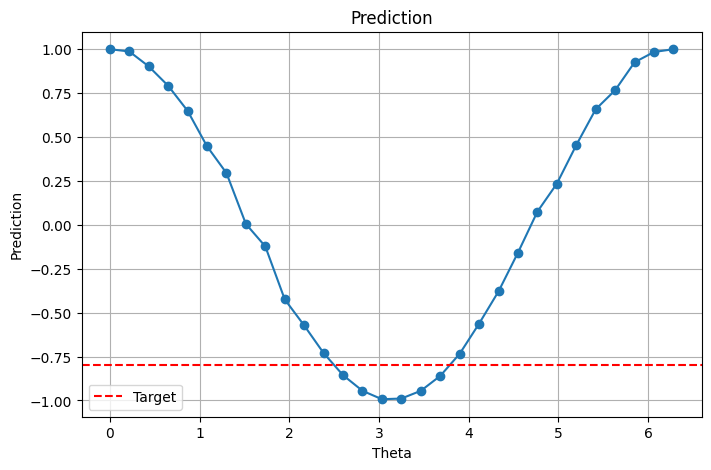

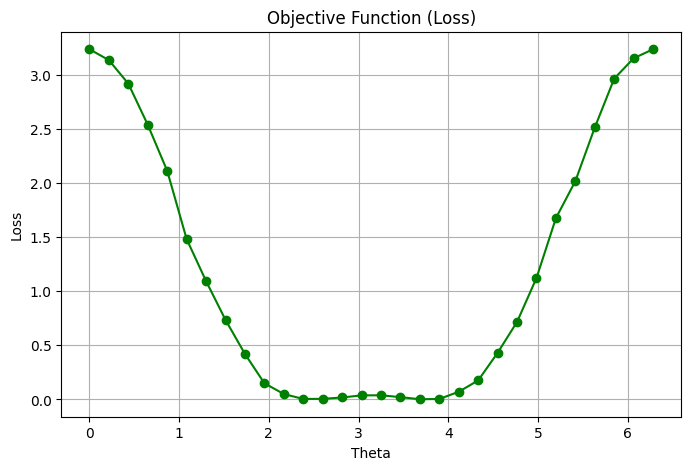

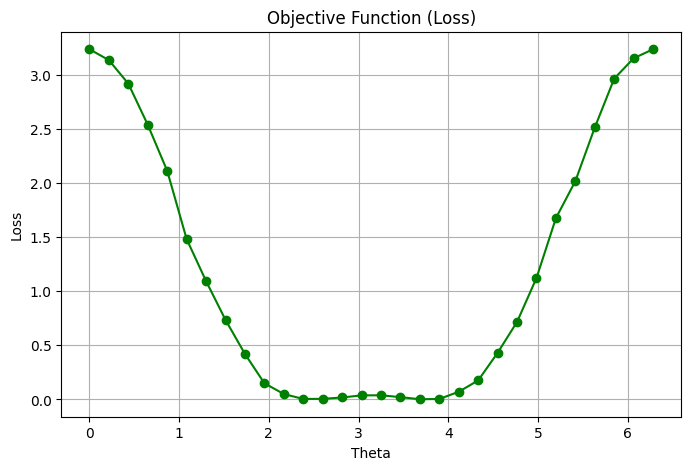



STEP 12. Best Parameter
Best Theta      : 3.6832
Prediction      : -0.8604
Target          : -0.8000
Loss            : 0.00174698
Lab Complete


In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit import transpile

from qiskit.circuit import Parameter

from qiskit_aer import AerSimulator

# ============================================================
# STEP 2. Parameterized Quantum Circuit 생성
# ============================================================

print("=" * 80)
print("STEP 2. Parameterized Quantum Circuit")
print("=" * 80)

# 학습 대상 Parameter
theta = Parameter("θ")

# 1-Qubit Circuit
qc = QuantumCircuit(1)

# Parameterized Gate
qc.ry(theta, 0)

# Measurement
qc.measure_all()

print(qc.draw())

# ============================================================
# STEP 3. Quantum Simulator 준비
# ============================================================

print("\n")
print("=" * 80)
print("STEP 3. Aer Simulator")
print("=" * 80)

simulator = AerSimulator()

shots = 2048

print("Backend :", simulator)
print("Shots   :", shots)

# ============================================================
# STEP 4. Prediction Function 구현
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4. Prediction Function")
print("=" * 80)

def predict(theta_value):
    """
    Parameter를 입력받아
    Quantum Circuit을 실행하고
    Prediction(Expectation Value)을 반환
    """

    # --------------------------------------
    # Parameter Binding
    # --------------------------------------
    bound = qc.assign_parameters(
        {theta: theta_value}
    )

    # --------------------------------------
    # Compile
    # --------------------------------------
    compiled = transpile(
        bound,
        simulator
    )

    # --------------------------------------
    # Run
    # --------------------------------------
    job = simulator.run(
        compiled,
        shots=shots
    )

    result = job.result()

    counts = result.get_counts()

    # --------------------------------------
    # Probability
    # --------------------------------------
    p0 = counts.get("0", 0) / shots
    p1 = counts.get("1", 0) / shots

    # --------------------------------------
    # Prediction (<Z> = p0 - p1)
    # --------------------------------------
    prediction = p0 - p1

    return prediction

# ============================================================
# STEP 5. Prediction Test
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5. Prediction Test")
print("=" * 80)

test_angles = [
    0,
    np.pi / 2,
    np.pi
]

for angle in test_angles:
    pred = predict(angle)
    print(f"Theta : {angle:.3f}")
    print(f"Prediction : {pred:.4f}")
    print("-" * 40)

# ============================================================
# STEP 6. Target 설정
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6. Target")
print("=" * 80)

target = -0.8

print("Target :", target)

# ============================================================
# STEP 7. Objective Function 구현
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7. Objective Function")
print("=" * 80)

def objective(theta_value):
    """
    Optimizer가 호출할 공통 Objective Function
    """
    prediction = predict(theta_value)
    loss = (prediction - target) ** 2
    return loss

print("Objective Function 생성 완료")

# ============================================================
# STEP 8. Objective Function Test
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8. Objective Function Test")
print("=" * 80)

test_parameters = [
    0.1,
    1.0,
    2.5
]

for theta_value in test_parameters:
    prediction = predict(theta_value)
    loss = objective(theta_value)
    print(f"Theta      : {theta_value:.3f}")
    print(f"Prediction : {prediction:.4f}")
    print(f"Loss       : {loss:.6f}")
    print("-" * 50)

# ============================================================
# STEP 9. Parameter Sweep
# ============================================================

print("\n")
print("=" * 80)
print("STEP 9. Parameter Sweep")
print("=" * 80)

angles = np.linspace(
    0,
    2 * np.pi,
    30
)

predictions = []
losses = []

for angle in angles:
    prediction = predict(angle)
    loss = objective(angle)
    predictions.append(prediction)
    losses.append(loss)

print("Parameter Sweep 완료")
print("Total Samples :", len(angles))

# ============================================================
# STEP 10. Prediction Graph
# ============================================================

fig1 = plt.figure(figsize=(8, 5))

plt.plot(
    angles,
    predictions,
    marker="o"
)

plt.axhline(
    y=target,
    color="red",
    linestyle="--",
    label="Target"
)

plt.title("Prediction")
plt.xlabel("Theta")
plt.ylabel("Prediction")
plt.grid(True)
plt.legend()
display(fig1)
plt.show()

# ============================================================
# STEP 11. Loss Graph
# ============================================================

fig2 = plt.figure(figsize=(8, 5))

plt.plot(
    angles,
    losses,
    marker="o",
    color="green"
)

plt.title("Objective Function (Loss)")
plt.xlabel("Theta")
plt.ylabel("Loss")
plt.grid(True)
display(fig2)
plt.show()

# ============================================================
# STEP 12. Best Parameter 찾기
# ============================================================

print("\n")
print("=" * 80)
print("STEP 12. Best Parameter")
print("=" * 80)

best_index = np.argmin(losses)

best_theta = angles[best_index]
best_prediction = predictions[best_index]
best_loss = losses[best_index]

print(f"Best Theta      : {best_theta:.4f}")
print(f"Prediction      : {best_prediction:.4f}")
print(f"Target          : {target:.4f}")
print(f"Loss            : {best_loss:.8f}")

print("=" * 80)
print("Lab Complete")
print("=" * 80)